# Derivatives from data

Last class we computed $f'(x)$ in two ways: **symbolically** (SymPy) and with **finite differences**. Today:

| part | question | tool |
|---|---|---|
| **A** | how small should the step $h$ be? | the V-shaped error plot |
| **B** | we only have a **table of values**, no function: how do we get $f'$? | central differences on data |

We use the same function as last class:
$$ f(x) = x^2 \sin x \; e^{-x/2}, \qquad x_0 = 1. $$

The finite-difference formulas from last class are now in the file **`finite_differences.py`**. Keep it in the same folder as this notebook. Run the first cell first, then run the notebook from top to bottom.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
"""Finite-difference formulas for the first derivative.

Use in a notebook with
    from finite_differences import forward, backward, central, five_point

All formulas follow from Taylor's theorem:
    f(x +- h) = f(x) +- h f'(x) + h^2/2 f''(x) +- h^3/6 f'''(x) + ...
"""


def forward(f, x, h):
    """Forward difference (f(x+h) - f(x)) / h.  Error O(h)."""
    return (f(x + h) - f(x)) / h


def backward(f, x, h):
    """Backward difference (f(x) - f(x-h)) / h.  Error O(h)."""
    return (f(x) - f(x - h)) / h


def central(f, x, h):
    """Central difference (f(x+h) - f(x-h)) / (2h).  Error O(h^2)."""
    return (f(x + h) - f(x - h)) / (2 * h)


def five_point(f, x, h):
    """5-point central difference.  Error O(h^4)."""
    return (-f(x + 2 * h) + 8 * f(x + h) - 8 * f(x - h) + f(x - 2 * h)) / (12 * h)


# a list to loop over, with matching names
FD_NAMES = ["forward", "backward", "central", "5-point"]
FD_METHODS = [forward, backward, central, five_point]


### The function and its exact derivative

We need an **exact** $f'$ to measure errors. By the product rule (or from SymPy last class):
$$ f'(x) = e^{-x/2}\left(2x\sin x + x^2\cos x - \tfrac{x^2}{2}\sin x\right). $$

In [33]:
def f(x):
    return x**2 * np.sin(x) * np.exp(-x/2)

def df_exact(x):
    return np.exp(-x/2) * (2*x*np.sin(x) + x**2*np.cos(x) - 0.5*x**2*np.sin(x))

x0 = 1.0
exact = df_exact(x0)
print(f"f(1)  = {f(x0):.15f}")
print(f"f'(1) = {exact:.15f}")

f(1)  = 0.510377951544573
f'(1) = 1.093276841339319


To use a function from the `.py` file, call it like any other function:

In [34]:
print("central, h = 0.1:", central(f, x0, 0.1), "   error:", abs(central(f, x0, 0.1) - exact))

central, h = 0.1: 1.0879418777721521    error: 0.005334963567166895


## Part A. Choosing $h$: the V-shaped error plot

We compute the error of each formula for many step sizes $h$, from $10^{-15}$ to $1$, and plot it on a log-log plot.

`np.logspace(-15, 0, 151)` gives 151 values of $h$, evenly spaced on a log scale. The formulas work with NumPy arrays, so we pass all of them at once.

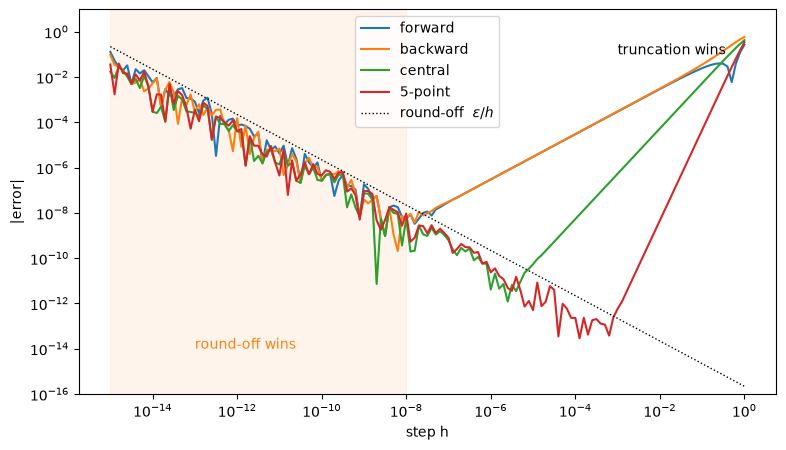

In [35]:
hs = np.logspace(-15, 0, 151)

fig, ax = plt.subplots(figsize=(9, 5))
for name, D in zip(FD_NAMES, FD_METHODS):
    err = np.abs(D(f, x0, hs) - exact)
    ax.loglog(hs, err + 1e-20, label=name)          # + 1e-20: avoid log(0)
ax.loglog(hs, 2.2e-16 / hs, "k:", lw=1, label=r"round-off  $\varepsilon/h$")
ax.axvspan(1e-15, 1e-8, color="tab:orange", alpha=0.08)
ax.text(1e-13, 1e-14, "round-off wins", color="tab:orange")
ax.text(1e-3, 1e-1, "truncation wins")
ax.set_xlabel("step h"); ax.set_ylabel("|error|")
ax.set_ylim(1e-16, 1e1); ax.legend(loc="lower right")
ax.legend(loc="upper center")
plt.show()

- **Large $h$ (right): truncation error.** The Taylor terms we dropped. It falls as $h^p$: slope 1 (forward, backward), 2 (central), 4 (5-point).
- **Small $h$ (left): round-off error.** $f(x+h) \approx f(x)$, so their difference loses digits, and we divide by a tiny $h$. It grows like $\varepsilon/h$, with $\varepsilon \approx 2.2\times10^{-16}$.
- Each curve is a **V**. The **best $h$** is at the bottom of the V. Read off from the plot (ignore the single lucky dips on the left, where round-off makes the curves jagged):

| formula | best $h$ | best error |
|---|---|---|
| forward, backward | $\approx 10^{-8}$ | $\approx 10^{-8}$ |
| central | $\approx 10^{-5}$ | $\approx 10^{-11}$ |
| 5-point | $\approx 10^{-3}$ | $\approx 10^{-13}$ |

**Never exact**: even at the best $h$ we lose 3 to 8 of the 16 digits.

## Part B. Derivatives from data (central differences)

Often we do **not** have a function to call. We have a **table**: measurements, or numbers saved by another program:
$$ (x_0, f_0),\ (x_1, f_1),\ \dots,\ (x_N, f_N), \qquad x_{i+1} - x_i = h. $$

Two things change:
- We **cannot** evaluate $f(x+h)$ for an $h$ of our choice. **$h$ is fixed by the data.**
- At the two ends there is a neighbour on **one side only**.

### Step 1: the table of values

We make the table from $f$ here, but from now on we pretend we only have the two arrays `xs` and `fs`.

In [36]:
xs = np.linspace(0, 10, 41)          # 41 points, spacing h = 0.25
fs = f(xs)                           # the "measured" values
h  = xs[1] - xs[0]

print("h =", h)
print(f"{'i':>3s} {'x_i':>6s} {'f_i':>10s}")
for i in range(5):
    print(f"{i:3d} {xs[i]:6.2f} {fs[i]:10.5f}")
print("...")

h = 0.25
  i    x_i        f_i
  0   0.00    0.00000
  1   0.25    0.01365
  2   0.50    0.09334
  3   0.75    0.26352
  4   1.00    0.51038
...


### Step 2: interior points, central difference

At an interior point $x_i$ both neighbours exist:
$$ f'_i \approx \frac{f_{i+1} - f_{i-1}}{2h}, \qquad \text{error} = O(h^2). $$

With NumPy **slices** we do all interior points at once:
- `fs[2:]` is $f_2, f_3, \dots, f_N$ (the right neighbours $f_{i+1}$),
- `fs[:-2]` is $f_0, f_1, \dots, f_{N-2}$ (the left neighbours $f_{i-1}$),

for $i = 1, \dots, N-1$.

In [37]:
d_interior = (fs[2:] - fs[:-2]) / (2*h)      # f'_1, ..., f'_{N-1}

print("number of interior points:", len(d_interior))
print("f'(x_2) from data:", d_interior[1], "   exact:", df_exact(xs[2]))

number of interior points: 39
f'(x_2) from data: 0.4997517347778009    exact: 0.4975703583807184


### Step 3: the two end points

At $x_0$ there is no $f_{-1}$, and at $x_N$ no $f_{N+1}$. Plain forward/backward differences would only be $O(h)$. Instead we use the **two** points on the side we have, $f_1$ and $f_2$, and combine them so that the $f''$ term cancels, as in the central difference.

**Where it comes from.** Taylor's theorem at $x_0$, with steps $h$ and $2h$:
$$ f_1 = f_0 + h f'_0 + \tfrac{h^2}{2} f''_0 + \tfrac{h^3}{6} f'''_0 + \dots $$
$$ f_2 = f_0 + 2h f'_0 + 2h^2 f''_0 + \tfrac{4h^3}{3} f'''_0 + \dots $$
Multiply the first line by 4 and subtract the second. The $f''$ terms cancel, since $4\cdot\tfrac{h^2}{2} - 2h^2 = 0$:
$$ 4f_1 - f_2 = 3f_0 + 2h f'_0 - \tfrac{2h^3}{3} f'''_0 + \dots $$
Solve for $f'_0$:
$$ f'_0 \approx \frac{-3f_0 + 4f_1 - f_2}{2h}, \qquad \text{error} \approx \frac{h^2}{3} f'''_0 = O(h^2). $$
At the right end, do the same with steps $-h$ and $-2h$ (replace $h$ by $-h$, and $f_1, f_2$ by $f_{N-1}, f_{N-2}$):
$$ f'_N \approx \frac{3f_N - 4f_{N-1} + f_{N-2}}{2h}. $$

Both are $O(h^2)$, like the central difference, but with an error twice as large ($\tfrac{h^2}{3}$ instead of $\tfrac{h^2}{6}$).

In [38]:
d_first = (-3*fs[0] + 4*fs[1] - fs[2]) / (2*h)
d_last  = ( 3*fs[-1] - 4*fs[-2] + fs[-3]) / (2*h)
d_bwd   = (fs[-1] - fs[-2]) / h                     # plain backward, for comparison

print(f"x = {xs[0]}:  3-point {d_first:9.5f}                       exact {df_exact(xs[0]):9.5f}")
print(f"x = {xs[-1]}: 3-point {d_last:9.5f}   plain backward {d_bwd:9.5f}   exact {df_exact(xs[-1]):9.5f}")

x = 0.0:  3-point  -0.07752                       exact   0.00000
x = 10.0: 3-point  -0.46142   plain backward  -0.53859   exact  -0.45539


### Step 4: all together

We put Steps 2 and 3 into one function, `derivative_from_data(fvals, h)`, which takes a table of values and returns the derivative at every point.

In [39]:
def derivative_from_data(fvals, h):
    # derivative of tabulated values f_0, ..., f_N with spacing h
    fvals = np.asarray(fvals, dtype=float)
    d = np.empty_like(fvals)
    d[1:-1] = (fvals[2:] - fvals[:-2]) / (2*h)                    # interior: central
    d[0]    = (-3*fvals[0] + 4*fvals[1] - fvals[2]) / (2*h)        # left end: one-sided 3-point
    d[-1]   = ( 3*fvals[-1] - 4*fvals[-2] + fvals[-3]) / (2*h)     # right end: one-sided 3-point
    return d

We plot it against the exact derivative (which we would **not** have for real data; here it is our check).

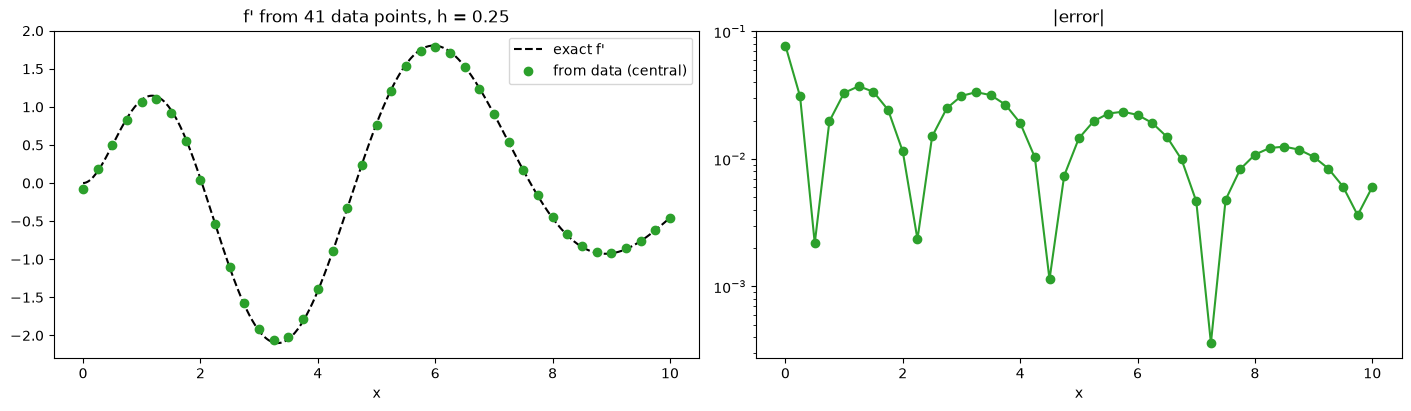

In [40]:
d = derivative_from_data(fs, h)
xx = np.linspace(0, 10, 400)

fig, axs = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
axs[0].plot(xx, df_exact(xx), "k--", lw=1.5, label="exact f'")
axs[0].plot(xs, d, "o", color="tab:green", label="from data (central)")
axs[0].set_title(f"f' from {len(xs)} data points, h = {h}"); axs[0].legend()
axs[1].semilogy(xs, np.abs(d - df_exact(xs)), "o-", color="tab:green")
axs[1].set_title("|error|")
for ax in axs: ax.set_xlabel("x")
plt.show()

### Step 5: more data points, smaller error

The only way to make $h$ smaller is **more data**. Central differences are $O(h^2)$: halve $h$ and the error should drop by $2^2 = 4$.

In [41]:
print(f"{'N':>5s} {'h':>10s} {'max |error|':>13s} {'ratio':>7s}")
prev = None
for N in [41, 81, 161, 321, 641]:
    xs_N = np.linspace(0, 10, N)
    h_N  = xs_N[1] - xs_N[0]
    err  = np.max(np.abs(derivative_from_data(f(xs_N), h_N) - df_exact(xs_N)))
    ratio = "" if prev is None else f"{prev/err:7.2f}"
    print(f"{N:5d} {h_N:10.5f} {err:13.2e} {ratio}")
    prev = err

    N          h   max |error|   ratio
   41    0.25000      7.75e-02 
   81    0.12500      2.53e-02    3.06
  161    0.06250      7.07e-03    3.58
  321    0.03125      1.86e-03    3.80
  641    0.01562      4.77e-04    3.90


The ratio approaches 4: the error is $O(h^2)$.

### Step 6: NumPy does it too

`np.gradient(fs, h, edge_order=...)` computes the derivative of a table of values.
- **Interior points:** always the central difference $(f_{i+1} - f_{i-1})/2h$.
- **End points:** `edge_order` chooses the formula, by its **order** in $h$:

| `edge_order` | formula at the ends | error at the ends |
|---|---|---|
| `1` (the default) | plain forward / backward, $(f_1 - f_0)/h$ | $O(h)$ |
| `2` | one-sided 3-point, $(-3f_0 + 4f_1 - f_2)/2h$ | $O(h^2)$ |

So `edge_order=2` is exactly our `derivative_from_data`, and the ends are as accurate as the interior. Always pass `edge_order=2`: the default `1` makes the two end points less accurate than the rest.

In [42]:
d_np2 = np.gradient(fs, h, edge_order=2)
d_np1 = np.gradient(fs, h)                       # default: edge_order=1

print("edge_order=2, largest difference from our function:", np.max(np.abs(d_np2 - d)))
print()
print(f"{'':14s} {'x = 0':>10s} {'x = 10':>10s}")
print(f"{'exact':14s} {df_exact(xs[0]):10.5f} {df_exact(xs[-1]):10.5f}")
print(f"{'edge_order=2':14s} {d_np2[0]:10.5f} {d_np2[-1]:10.5f}")
print(f"{'edge_order=1':14s} {d_np1[0]:10.5f} {d_np1[-1]:10.5f}")

edge_order=2, largest difference from our function: 5.551115123125783e-17

                    x = 0     x = 10
exact             0.00000   -0.45539
edge_order=2     -0.07752   -0.46142
edge_order=1      0.05458   -0.53859


- At $x = 10$, `edge_order=2` is much closer to the exact value.
- At $x = 0$, `edge_order=1` happens to win: here $f''(0) = 0$, so the leading error term $\tfrac{h}{2}f''$ of the forward difference vanishes. This is luck; in general `edge_order=2` is the safe choice.

## Comparison at $x_0 = 1$

In [43]:
names  = ["forward,  h = 1e-8", "central,  h = 1e-5", "5-point,  h = 1e-3"]
values = [forward(f, x0, 1e-8), central(f, x0, 1e-5), five_point(f, x0, 1e-3)]

print(f"{'method':20s} {'derivative':>20s} {'error':>10s}")
for name, v in zip(names, values):
    print(f"{name:20s} {float(v):20.15f} {abs(v - exact):10.1e}")

method                         derivative      error
forward,  h = 1e-8      1.093276835728574    5.6e-09
central,  h = 1e-5      1.093276841285240    5.4e-11
5-point,  h = 1e-3      1.093276841338743    5.8e-13


| | finite differences | symbolic (SymPy) |
|---|---|---|
| needs | **values** of $f$ | a **formula** for $f$ |
| choose a step $h$? | yes | no |
| accuracy | $10^{-8}$ to $10^{-13}$ | exact |
| works on a table of data? | **yes** | no |

- **Only data?** Central differences inside, one-sided 3-point at the ends (`np.gradient(fs, h, edge_order=2)`).
- **Have a formula?** Differentiate it symbolically, and check with a central difference.

## Exercises

**Syntax**

| task | call |
|---|---|
| finite differences | `central(f, x, h)`, `five_point(f, x, h)` |
| derivative from data | `derivative_from_data(fs, h)` or `np.gradient(fs, h, edge_order=2)` |
| log-log plot | `ax.loglog(h, err)`; values `np.logspace(a, b, n)` |

**Exercise 1 (V-shape).** Let $f(x) = \dfrac{\ln(1 + x^2)}{1 + x}$, $x_0 = 1$.

(a) Compute the exact $f'(1)$ by hand with the quotient rule (or with SymPy, as last class).

(b) Using (a) as the reference, plot the error of `central` and `five_point` against $h \in [10^{-15}, 1]$ on a log-log plot. Read off the best $h$ and the smallest error for each.

In [44]:
# Exercise 1


**Exercise 2 (data).** A car's position (in m) is recorded every $0.5$ s:

| $t$ (s) | 0 | 0.5 | 1.0 | 1.5 | 2.0 | 2.5 | 3.0 |
|---|---|---|---|---|---|---|---|
| $s$ (m) | 0.0 | 2.6 | 10.1 | 22.4 | 39.8 | 61.9 | 89.1 |

As NumPy arrays:
```python
t = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])        # time (s)
s = np.array([0.0, 2.6, 10.1, 22.4, 39.8, 61.9, 89.1])   # position (m)
```

(a) Compute the velocity $v = ds/dt$ at every time with `derivative_from_data`. Check with `np.gradient`.

(b) Compute the acceleration $a = dv/dt$ by applying the same function to your velocities. Is the acceleration roughly constant?

(c) Why can't you make $h$ smaller here, as we did in Part A?

In [45]:
# Exercise 2

t = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])        # time (s)
s = np.array([0.0, 2.6, 10.1, 22.4, 39.8, 61.9, 89.1])   # position (m)

